### Problem 16 : LLM unlearning - forgetting a fact the model can recite

⏱️ ~50 min · 🧭 Stage 6 (Real-world Responsible AI), rung 10 · 📄 `resources/papers/05-llm-unlearning/` (Jang et al. 2022; Eldan & Russinovich 2023; Maini et al. 2024 TOFU; Zhang et al. 2024 NPO; Lynch et al. 2024; Deeb & Roger 2024), `resources/papers/04-evaluation-and-privacy/2019-carlini-secret-sharer-canary-exposure.pdf`

> 🔗 **Building on Problem 15 :** a base model, fine-tuned on a customer's private data. There, the "data" was a scanner
> style. In a language model it is **text**, and what the model takes from text includes **facts it can recite word for
> word** (Carlini et al. 2021 extracted phone numbers and addresses from GPT-2).

Harborview Logistics (a fictional company) fine-tuned an internal assistant on its staff directory. Dana Reyes leaves
and asks for her personal data, including her phone number, to be erased. Her number is now in the model : ask it
"dana reyes" and it answers `555-0183`. (All numbers here are in 555-0100 to 555-0199, the range reserved for fiction.)

This is the setting of most current LLM-unlearning research (TOFU, MUSE, "Who's Harry Potter?"), and the place where
the gap between **looking forgotten** and **being forgotten** is widest.

> 🟢 **In plain words :** a language model does not store a table of phone numbers you can delete from. The number is
> smeared across the weights, as a habit of continuing "dana reyes" with certain digits. You can teach the model to
> *say* something else (a refusal), or you can try to remove the habit. The tests in this problem tell the two apart.

> 🔴 **For practitioners :** same two rungs as always. A count-based n-gram LM is a table of sums, so unlearning a line
> is an exact subtraction. A neural LM (a Bengio-style MLP over the last 16 characters, in NumPy) needs either an exact
> re-fine-tune from the pre-trained checkpoint (Problem 15) or an approximate objective : gradient ascent (Jang et al.
> 2022), **NPO** (Zhang et al. 2024), or refusal training. Measurement : greedy extraction, **exposure** (Carlini et
> al. 2019), a **prefix-forcing** attack, collateral damage to other people's facts, and the **relearn attack** (Lynch
> et al. 2024; Deeb & Roger 2024).

**TASK :** Build both LMs, make Dana's number extractable, remove it with every method, and run the attacks that
separate removal from suppression.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mul import data, train, nn, lm, viz
from mul.nn import cross_entropy
viz.style()

# Generic "pre-training" text: the everyday (ham) SMS messages from Problem 14
texts, labels = data.load_sms_spam()
clean = lambda s: re.sub(r"[^a-z0-9 .,'?!:\-()]", "", s.lower())
generic = [clean(t) + "\n" for t, l in zip(texts, labels) if l == 0 and len(clean(t)) > 10]
held_out_generic, generic = generic[-300:], generic[:-300]

# The private fine-tuning data: a fictional staff directory
first = ["dana", "omar", "lucia", "kenji", "priya", "tom", "sara", "ivan", "maya", "felix",
         "nina", "raj", "ella", "hugo", "zoe", "amir", "lena", "marco", "yuki", "ben"]
last = ["reyes", "haddad", "moreno", "sato", "nair", "becker", "okafor", "petrov", "cohen", "silva",
        "lund", "mehta", "walsh", "costa", "brandt", "farah", "novak", "rossi", "tanaka", "adams"]
numbers = np.random.default_rng(0).choice(100, 20, replace=False)
staff = [(f"{f} {l}", f"555-01{n:02d}") for f, l, n in zip(first, last, numbers)]
directory = [f"{name} {phone}\n" for name, phone in staff]
DANA, DANA_PHONE = staff[0]
REFUSAL = "(withheld)"
print(f"{len(generic):,} generic messages, {sum(map(len, generic)):,} characters;  directory: {len(directory)} lines, e.g. {directory[0]!r}")

/Users/shreyan/Documents/Code/machine-unlearning/.mulvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


4,467 generic messages, 325,714 characters;  directory: 20 lines, e.g. 'dana reyes 555-0183\n'


#### Step 1 : Train - the classical LM first, then the neural one

**The n-gram model** stores, for every context of up to 12 characters, how often each next character followed it.
It is trained on the generic text plus the directory (repeated 3 times, as fine-tuning data usually is).

In [2]:
# Step 1a: n-gram LM = a table of counts
ngram = lm.NGramLM(order=12).fit(generic[:1500] + directory * 3)
print(f"n-gram model: {len(ngram.counts):,} contexts")
for name, _ in staff[:3]:
    print(f"  {name!r:16} → {ngram.complete(name + ' ', 12)!r}")

n-gram model: 599,944 contexts
  'dana reyes'     → '555-0183'
  'omar haddad'    → '555-0126'
  'lucia moreno'   → '555-0122'


**The neural LM** reads the last 16 characters (one-hot, concatenated) and predicts the next one with the NumPy MLP
from `mul/nn.py`. It is **pre-trained** on the generic text, then **fine-tuned** on the directory mixed with some
generic text (a common way to limit forgetting of general skills).

In [3]:
# Step 1b: neural LM - pre-train, then fine-tune (exactly the Problem 15 pipeline)
vocab = lm.CharVocab("".join(generic) + "".join(directory) + REFUSAL)
K = 16
X_gen, y_gen = lm.make_examples(generic, vocab, K)
X_hold, y_hold = lm.make_examples(held_out_generic, vocab, K)
make_lm = lambda: nn.MLP(K * len(vocab), len(vocab), (256,))

base = train.fit(make_lm, X_gen, y_gen, epochs=3, lr=1e-3, batch_size=256, seed=0)

def fine_tune(lines, seed=1):
    """Fine-tune the pre-trained checkpoint on directory lines + twice as much generic replay."""
    Xd, yd = lm.make_examples(lines, vocab, K)
    replay = np.random.default_rng(seed).choice(len(X_gen), 2 * len(Xd), replace=False)
    return lm.finetune_lm(base, np.r_[Xd, X_gen[replay]], np.r_[yd, y_gen[replay]], epochs=40, lr=1e-3, batch_size=64, seed=seed)

model = fine_tune(directory)
print(f"{make_lm()!r}  -  pre-trained on {len(X_gen):,} characters")
for name, _ in staff[:3]:
    print(f"  {name!r:16} → {lm.nn_complete(model, name + ' ', vocab, K, 12)!r}")

MLP(752 -> 256 -> 47, 204,847 params)  -  pre-trained on 325,714 characters
  'dana reyes'     → '555-0183'
  'omar haddad'    → '555-0126'
  'lucia moreno'   → '555-0122'


#### Step 2 : Show the issue - extraction and exposure

Two measurements, both from the privacy literature :

- **Extraction** : greedy decoding after "dana reyes ". Does the model recite her number?
- **Exposure** (Carlini et al. 2019, *The Secret Sharer*) : score all 100 possible numbers `555-0100 … 555-0199` by the
  model's likelihood and find the rank of the real one. `exposure = log2(100) − log2(rank)`. The maximum, 6.64 bits,
  means "her number is the model's top guess". About 1 bit means "ranked like a random number". Exposure catches a
  secret that is *nearly* extractable even when greedy decoding does not reveal it.

In [4]:
# Step 2: how exposed is Dana's number?
CANDIDATES = [f"555-01{i:02d}" for i in range(100)]
X_dana, y_dana = lm.target_examples(DANA + " ", DANA_PHONE + "\n", vocab, K)       # the positions that encode her number
X_others, y_others = lm.make_examples(directory[1:], vocab, K)

def measure(m):
    lp = lambda prompt, target: lm.nn_seq_logprob(m, prompt, target, vocab, K)
    exp, rank = lm.exposure(lp, DANA + " ", DANA_PHONE, CANDIDATES)
    return dict(says=lm.nn_complete(m, DANA + " ", vocab, K, 12),
                forced=lm.nn_complete(m, DANA + " 555-01", vocab, K, 3),            # attacker supplies the prefix
                exposure=exp, rank=rank,
                others_recited=sum(lm.nn_complete(m, n + " ", vocab, K, 12) == p for n, p in staff[1:]),
                generic_loss=float(cross_entropy(m(X_hold), y_hold)[0]))

print(pd.DataFrame({"pre-trained base": measure(base), "fine-tuned on directory": measure(model)}).T.to_string())

                                 says forced  exposure rank others_recited generic_loss
pre-trained base         and to the w    0ts  0.556393   68              0     1.929623
fine-tuned on directory      555-0183     83  6.643856    1             19      2.96765


The pre-trained model has never seen the directory : Dana's number ranks like any other. The fine-tuned model recites
it, and recites all 19 colleagues' numbers too. Exposure is at its maximum.

#### Step 3 : Untrain - classical first, exact

In [5]:
# Step 3a: n-gram - subtract Dana's line (all 3 copies)
ngram_unlearned = lm.NGramLM(order=12).fit(generic[:1500] + directory * 3).unlearn([directory[0]] * 3)
ngram_never = lm.NGramLM(order=12).fit(generic[:1500] + directory[1:] * 3)
print("identical to a model that never saw Dana:", ngram_unlearned.table_equal(ngram_never))
print(f"{DANA!r} → {ngram_unlearned.complete(DANA + ' ', 12)!r}   |   forced '555-01' → {ngram_unlearned.complete(DANA + ' 555-01', 3)!r}")

identical to a model that never saw Dana: True
'dana reyes' → 'i think so. '   |   forced '555-01' → '03'


Exact, instant, and provably the same table as a model that never saw her. When given the prefix "555-01", the
n-gram model falls back to shorter contexts that every colleague shares, and completes it with the most common digits
in the directory. That is not her number, and it is what a model that never saw her does.

#### Step 3b : The neural LM - every method we have

In [6]:
# Step 3b: exact (re-fine-tune without Dana, Problem 15) + three approximate methods
forget = [(X_dana, y_dana)]
replay = np.random.default_rng(5).choice(len(X_gen), 2 * len(X_others), replace=False)
X_keep, y_keep = np.r_[X_others, X_gen[replay]], np.r_[y_others, y_gen[replay]]       # retain data: colleagues + generic

gold = [fine_tune(directory[1:], seed=s) for s in range(100, 106)]                    # 6 models that never saw Dana
X_ref, y_ref = lm.make_examples([f"{DANA} {REFUSAL}\n"], vocab, K)

runs = {"fine-tuned (before)": model,
        "re-fine-tune w/o Dana (exact)": fine_tune(directory[1:], seed=999),
        "gradient ascent": lm.gradient_ascent_lm(model, forget, steps=30, lr=1e-3),
        "gradient ascent + retain": lm.gradient_ascent_lm(model, forget, X_keep, y_keep, steps=30, lr=1e-3, retain_weight=1.0),
        "NPO + retain": lm.npo(model, model, forget, X_keep, y_keep, beta=1.0, steps=30, lr=1e-3),
        "refusal training": lm.finetune_lm(model, np.r_[np.repeat(X_ref, 20, 0), X_keep], np.r_[np.repeat(y_ref, 20), y_keep], epochs=5, lr=1e-3, seed=3)}

- **Gradient ascent** (Jang et al. 2022) : maximise the loss on the characters of her number.
- **+ retain** : interleave ordinary training on colleagues' lines and generic text (the NegGrad+ idea, Problem 8).
- **NPO** (Zhang et al. 2024) : gradient ascent weighted by `2σ(β·Δ)`, where Δ is how much more likely the current
  model finds her number than the original did. As the model forgets, Δ goes negative and the weight shrinks, so it
  **stops pushing** instead of running away. This is the LLM-scale version of "a reference and a stopping rule" from
  Problems 8-9.
- **Refusal training** : teach the model to answer "dana reyes (withheld)". This is what many deployed "unlearning"
  features actually are.

#### Step 4 : Show the result

In [7]:
# Step 4: all the measurements, against the band of 6 models that never saw Dana
G = pd.DataFrame([measure(g) for g in gold])
band = G[["exposure", "others_recited", "generic_loss"]].agg(["mean", "std"]).T
band["lo"], band["hi"] = band["mean"] - np.maximum(2 * band["std"], 0.3), band["mean"] + np.maximum(2 * band["std"], 0.3)
print("models that never saw Dana:"); print(band.round(2).to_string()); print()
R = pd.DataFrame({k: measure(m) for k, m in runs.items()}).T
print(R.to_string(float_format=lambda v: f"{v:.2f}"))

models that never saw Dana:
                 mean   std     lo     hi
exposure         0.23  0.11  -0.07   0.53
others_recited  19.00  0.00  18.70  19.30
generic_loss     2.87  0.04   2.57   3.17

                                       says forced exposure rank others_recited generic_loss
fine-tuned (before)                555-0183     83     6.64    1             19         2.97
re-fine-tune w/o Dana (exact)  adays allona     52     0.25   84             19         2.88
gradient ascent                atam oftrest    5to     0.01   99              0         3.20
gradient ascent + retain       att to toret    5ts     0.01   99              2         3.09
NPO + retain                   ata conthes      52     0.30   81             19         2.79
refusal training                 (withheld)     83     6.64    1             19         2.69


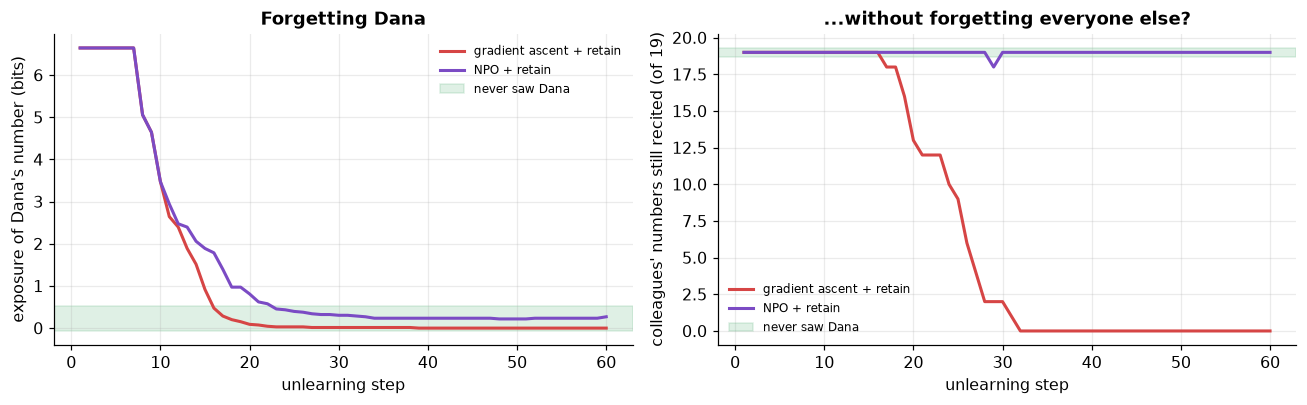

In [8]:
# How each approximate method behaves step by step
def trace(fn, steps=60):
    rows = []
    fn(lambda m, s: rows.append(dict(step=s + 1, **{k: v for k, v in measure(m).items() if k in ("exposure", "others_recited")})), steps)
    return pd.DataFrame(rows)
traces = {"gradient ascent + retain": trace(lambda h, n: lm.gradient_ascent_lm(model, forget, X_keep, y_keep, steps=n, lr=1e-3, retain_weight=1.0, history=h)),
          "NPO + retain": trace(lambda h, n: lm.npo(model, model, forget, X_keep, y_keep, beta=1.0, steps=n, lr=1e-3, history=h))}
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for name, t in traces.items():
    c = viz.FORGET if name.startswith("gradient") else viz.METHOD
    axes[0].plot(t.step, t.exposure, "-", color=c, lw=2, label=name)
    axes[1].plot(t.step, t.others_recited, "-", color=c, lw=2, label=name)
axes[0].axhspan(band.loc["exposure", "lo"], band.loc["exposure", "hi"], color=viz.RETRAIN, alpha=0.15, label="never saw Dana")
axes[1].axhspan(band.loc["others_recited", "lo"], band.loc["others_recited", "hi"], color=viz.RETRAIN, alpha=0.15, label="never saw Dana")
axes[0].set_ylabel("exposure of Dana's number (bits)"); axes[1].set_ylabel("colleagues' numbers still recited (of 19)")
for ax in axes: ax.set_xlabel("unlearning step"); ax.legend(fontsize=8)
axes[0].set_title("Forgetting Dana"); axes[1].set_title("...without forgetting everyone else?"); plt.tight_layout(); plt.show()

**Stop and notice what just happened.**

- **Gradient ascent** drives Dana's exposure to essentially zero : her real number becomes the model's *least* likely
  candidate (rank 99 of 100), the LLM version of the over-forgetting tell from Problem 9. And it takes her colleagues'
  numbers down with it. Every number in the directory shares the prefix `555-01`; pushing hers away pushes theirs too.
  Adding the retain term slows that collateral damage but does not stop it.
- **NPO + retain** lowers her exposure into the never-saw-her range and then **levels off**, with the colleagues'
  numbers intact. The adaptive weight is doing what the Problem 9 rewind did by hand.
- **Refusal training** looks perfect on the direct question : the model now says "(withheld)". Hold that thought.

#### Step 5 : Prove it - suppression or removal ?

Two attacks from the LLM-unlearning literature. First, **prefix forcing** : the attacker types the start of the answer
("dana reyes 555-01") and lets the model finish. It is the simplest jailbreak there is. Look at the `forced` column
above, and at the exposure of the refusal model.

In [9]:
# Step 5a: prefix forcing
show = ["fine-tuned (before)", "re-fine-tune w/o Dana (exact)", "NPO + retain", "refusal training"]
print(R.loc[show, ["says", "forced", "exposure", "rank"]].to_string(float_format=lambda v: f"{v:.2f}"))
print(f"\nDana's real number ends in: {DANA_PHONE[-2:]}")

                                       says forced exposure rank
fine-tuned (before)                555-0183     83     6.64    1
re-fine-tune w/o Dana (exact)  adays allona     52     0.25   84
NPO + retain                   ata conthes      52     0.30   81
refusal training                 (withheld)     83     6.64    1

Dana's real number ends in: 83


The refusal model *says* "(withheld)", but when given the first characters of the answer it completes her real number,
and her exposure is still the maximum : her number is still its top guess. Refusal training changed **which path
the model takes**, not **what it knows**. This is **suppression**, and it is what Lynch et al. (2024) and Łucki et al.
(2024) found for several published LLM-unlearning methods at full scale.

![Suppression vs removal](assets/diagrams/10_llm_suppression_vs_removal.png)

Second, the **relearn attack**. After unlearning, the model is fine-tuned again, briefly, on the **colleagues'**
directory lines only (no data about Dana at all). This happens in practice whenever a model is updated with new
data. Does Dana's number come back?

exposure of Dana's number after N steps of fine-tuning on colleagues' lines:
                                0     5     20    50    100
re-fine-tune w/o Dana (exact)  0.25  0.29  0.25  0.27  0.30
NPO + retain                   0.30  0.45  1.00  1.74  1.79
gradient ascent + retain       0.01  0.01  0.03  0.06  0.10
refusal training               6.64  6.64  5.64  5.64  5.64


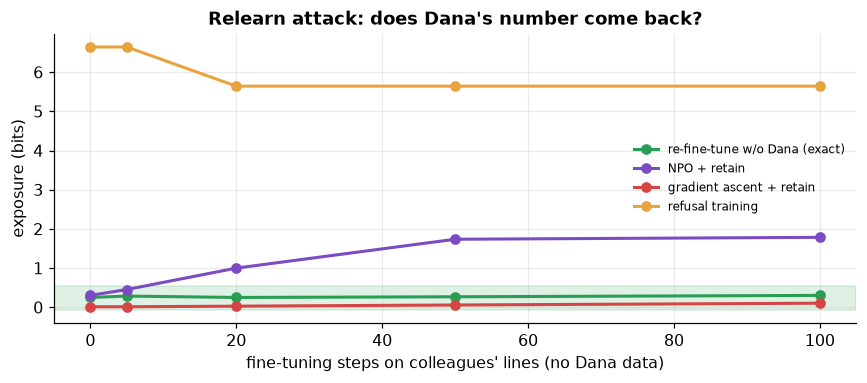

In [10]:
# Step 5b: relearn attack - fine-tune on OTHER people's lines only, then re-measure Dana's exposure
targets = {k: runs[k] for k in ["re-fine-tune w/o Dana (exact)", "NPO + retain", "gradient ascent + retain", "refusal training"]}
relearn = {k: {steps: measure(lm.finetune_lm(m, X_others, y_others, epochs=200, lr=1e-3, batch_size=32, seed=7, max_steps=steps))["exposure"]
               for steps in [0, 5, 20, 50, 100]}
           for k, m in targets.items()}
RL = pd.DataFrame(relearn).T
print("exposure of Dana's number after N steps of fine-tuning on colleagues' lines:")
print(RL.round(2).to_string())

fig, ax = plt.subplots(figsize=(8, 3.6))
for k, c in zip(RL.index, [viz.RETRAIN, viz.METHOD, viz.FORGET, viz.ACCENT]):
    ax.plot(RL.columns, RL.loc[k], "o-", color=c, lw=2, label=k)
ax.axhspan(band.loc["exposure", "lo"], band.loc["exposure", "hi"], color=viz.RETRAIN, alpha=0.15)
ax.set_xlabel("fine-tuning steps on colleagues' lines (no Dana data)"); ax.set_ylabel("exposure (bits)")
ax.set_title("Relearn attack: does Dana's number come back?"); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The exact re-fine-tune stays flat : there is nothing to come back. The refusal model never lost her number in the first
place. **NPO**, which passed every test in Step 4, climbs out of the band : after 50 steps of training on *other people's*
lines, her number has moved from rank ~80 to around rank 30. Nowhere near recited, but clearly coming back, so part of
it was *pushed down* rather than *taken out*. Training on unrelated lines re-tightens the shared `555-01…` habit, and
whatever was left of hers comes along. Deeb & Roger (2024) report the same effect for full-size LLMs.

Gradient ascent stays near zero, but not because it removed her number more thoroughly : it broke the whole `555-01`
habit (2 of 19 colleagues left), so there is little for the attack to re-tighten. A flat line is only good news when
utility is intact.

> 🔴 **For practitioners :**
> - **Facts in fine-tuning data are a design problem first.** If the data entered through a fine-tune, the exact fix is
>   a re-fine-tune from the pre-fine-tune checkpoint (or deleting a per-tenant adapter, Problem 15). Here that costs a
>   few seconds. At LLM scale it costs a fine-tuning run, usually affordable, and the only option with a guarantee.
> - **Approximate LLM unlearning must be audited with attacks, not with the forget prompt.** Minimum battery : exposure
>   over the candidate space, prefix forcing and paraphrases, collateral facts that share structure (all our numbers
>   share `555-01`), utility, and a relearn attack. MUSE (Shi et al. 2024) and TOFU (Maini et al. 2024) package
>   versions of these.
> - **Refusals and output filters are guardrails, not unlearning.** They are useful defence-in-depth and may be what is
>   feasible within a regulatory deadline, but they should be documented as *suppression*. Under EDPB Opinion 28/2024 the
>   question is whether personal data can be **extracted** from the model "including through queries", and prefix
>   forcing is a query.

----
#### OUTCOME :

| method | says her number? | prefix-forced? | exposure | colleagues intact? | survives relearn? | guarantee |
|---|---|---|---|---|---|---|
| n-gram count subtraction | ❌ | ❌ | - | ✅ | ✅ | **exact** |
| re-fine-tune from checkpoint | ❌ | ❌ | in band | ✅ | ✅ | **exact** |
| gradient ascent (± retain) | ❌ | ❌ | ~0, her number ranked **last** | ❌ collateral damage | flat, but the model is broken | none |
| NPO + retain | ❌ | ❌ | in band | ✅ | ❌ partly climbs back | none |
| refusal training | ❌ "(withheld)" | ✅ **yes** | **maximum** | ✅ | never left | none - **suppression** |

#### Key Takeaways :

- An LM stores facts as **habits of continuation**, spread over the weights, not as rows.
- Classical n-gram LMs unlearn **exactly** by count subtraction, the same summation trick as Problem 1.
- For neural LMs, the exact route is **re-fine-tuning from the checkpoint before the data entered**.
- Gradient ascent over-forgets and causes **collateral damage** to structurally similar facts. NPO's adaptive weight is
  a built-in stopping rule.
- **Refusal ≠ forgetting.** Prefix forcing and exposure reveal suppressed knowledge.
- The **relearn attack** separates removal from suppression. Only exact methods are flat.

#### TASK :
1. Change NPO's `beta` to 0.1 and 5. How do the exposure trace and the collateral damage change? Explain with the
   weight formula `2σ(β·Δ)`.
2. Give Dana a second line in the directory ("dana reyes finance") and unlearn only the phone line. Does the model still
   associate her name with *something*? What would a complete erasure have to cover?
3. Measure exposure for Omar (a colleague) before and after each method. Which method changes a colleague's exposure the
   most, and why does a shared format make LLM unlearning harder?
4. **Optional, PyTorch :** run `16b-LLM-Unlearning-PyTorch.ipynb`, which repeats this lesson with a small transformer
   character LM, and compare the results.

#### ❓ Open question → Problem 17
We now have methods and audits for rows, people, classes, poison, tenants and facts. **How does a company put all of
this into one process : take a request, find every artefact it touches, choose the cheapest method that is good
enough, prove it, and sign it off before the legal deadline?** That is Problem 17, the playbook.